# RoadSense: Robust Traffic Sign Recognition
## Phase 3: Robustness Test Bench
**Group 4 | Atria University**  
- **Primary Owner:** Raju (Robustness Test Bench — Code & Testing)  
- **Team:** Aseem (Leader), Manoj, Sohail  

---
### Objectives of Phase 3:
1. **Simulate Real-World Driving Corruptions:** Apply 5 realistic image degradations that occur in actual dashcam deployments.
2. **Stress-Test the Baseline CNN:** Evaluate the Phase 2 model (97.98% clean accuracy) under all 15 corruption conditions (5 types × 3 severity levels).
3. **Compute Mean Corruption Accuracy (mCA):** A single number summarising robustness across all degradation conditions.
4. **Measure Robustness Gap:** Clean Accuracy − mCA (how much the model degrades under real-world noise).
5. **Visualise Corruption Effects:** Show sample corrupted images at each severity level.
6. **Generate Degradation Curves:** Plot per-corruption accuracy vs severity level.
7. **Identify the Hardest Corruption:** Pinpoint which degradation hurts the model the most.

---
## Section 0: Environment Setup

In [1]:
import sys
from pathlib import Path

# Add project root to Python path
ROOT_DIR = Path().resolve().parent
sys.path.append(str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from PIL import Image
import torch
from torch.utils.data import DataLoader

from src.corruptions import CORRUPTIONS, SEVERITIES, apply_corruption
from src.models import BaselineCNN, count_parameters
from src.dataset import DATA_DIR, get_transforms, GTSRBDataset

RESULTS_DIR = ROOT_DIR / 'results'
FIG_DIR = RESULTS_DIR / 'figures'
CHECKPOINT_DIR = ROOT_DIR / 'checkpoints'
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f'PyTorch version : {torch.__version__}')
print(f'Device          : {"CUDA" if torch.cuda.is_available() else "CPU"}')
print(f'Corruptions     : {CORRUPTIONS}')
print(f'Severity levels : {SEVERITIES}')
print(f'Total conditions: {len(CORRUPTIONS) * len(SEVERITIES)}')

Corruptions implemented (src/corruptions.py):
  1. gaussian_noise     : sigma = [0.05, 0.10, 0.15]
  2. motion_blur        : kernel = [3, 7, 15]
  3. brightness_contrast: factor = [0.7/1.3, 0.5/1.5, 0.3/1.7]
  4. random_occlusion   : patch_ratio = [0.10, 0.20, 0.35]
  5. jpeg_compression   : quality = [60, 30, 10]
Total conditions: 5 corruptions x 3 severities = 15


---
## Section 1: What Are the 5 Corruptions?

Each corruption simulates a real-world image degradation scenario that a dashcam-mounted traffic sign recogniser would face in actual deployment:

| # | Corruption | Real-World Cause | Severity Params |
|---|---|---|---|
| 1 | **Gaussian Noise** | Camera sensor grain in low light / high ISO | σ = 18, 38, 65 |
| 2 | **Motion Blur** | Fast vehicle speed or camera shake | radius = 1.0, 2.0, 3.5 |
| 3 | **Brightness/Contrast** | Sun glare, tunnel darkness, night driving | contrast × brightness factors |
| 4 | **Random Occlusion** | Tree branch, lamppost, sticker covering sign | patch = 19%, 31%, 44% of image |
| 5 | **JPEG Compression** | Low-bitrate dashcam video, network transmission | quality = 40, 20, 8 |

**Severity Levels:**
- **Level 1 (Mild):** Barely noticeable degradation
- **Level 2 (Moderate):** Clearly visible but sign still readable
- **Level 3 (Severe):** Heavily degraded — very hard for humans too

---
## Section 2: Visualise Corruptions on Sample Images

In [2]:
# Load a few sample images from the test set for visualisation
test_csv = DATA_DIR / 'Test.csv'
df_test = pd.read_csv(test_csv)

# Pick one representative image per corruption demo
sample_row = df_test.iloc[42]  # arbitrary sample
sample_img = Image.open(DATA_DIR / sample_row['Path']).convert('RGB')
sample_img = sample_img.resize((96, 96), Image.BILINEAR)  # enlarge for display

CORRUPTION_LABELS = {
    'gaussian_noise':      'Gaussian Noise',
    'motion_blur':         'Motion Blur',
    'brightness_contrast': 'Brightness/Contrast',
    'random_occlusion':    'Random Occlusion',
    'jpeg_compression':    'JPEG Compression',
}

fig, axes = plt.subplots(len(CORRUPTIONS) + 1, 4, figsize=(14, 18))
fig.suptitle('Corruption Samples: All 5 Types × 3 Severity Levels\n(Class: Speed Limit 50 km/h)', 
             fontsize=14, fontweight='bold', y=1.01)

col_labels = ['Clean', 'Level 1 (Mild)', 'Level 2 (Moderate)', 'Level 3 (Severe)']
for col, label in enumerate(col_labels):
    axes[0][col].set_title(label, fontsize=11, fontweight='bold', color='#2c3e50')
    axes[0][col].axis('off')

for row_idx, corr in enumerate(CORRUPTIONS):
    ax_row = axes[row_idx + 1]
    ax_row[0].imshow(sample_img)
    ax_row[0].set_ylabel(CORRUPTION_LABELS[corr], fontsize=9, fontweight='bold', rotation=90, labelpad=8)
    ax_row[0].set_xticks([])
    ax_row[0].set_yticks([])

    for sev_idx, sev in enumerate(SEVERITIES):
        corrupted = apply_corruption(sample_img, corr, severity=sev, seed=42)
        ax_row[sev_idx + 1].imshow(corrupted)
        ax_row[sev_idx + 1].set_xticks([])
        ax_row[sev_idx + 1].set_yticks([])

plt.tight_layout()
out_path = FIG_DIR / 'phase3_corruption_samples_grid.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out_path}')

Running robustness benchmark on baseline_cnn (12,630 test images)...
gaussian_noise   L1: 93.24% | L2: 81.35% | L3: 65.85%
motion_blur      L1: 95.55% | L2: 77.36% | L3: 46.90%
brightness_contr L1: 97.47% | L2: 94.26% | L3: 77.01%
random_occlusion L1: 93.59% | L2: 82.83% | L3: 61.40%
jpeg_compression L1: 94.39% | L2: 89.13% | L3: 71.60%

Mean Corruption Accuracy (mCA): 81.46%
Robustness Gap (mCA - Clean): -16.52%
Worst condition: motion_blur L3 -> 46.90%


---
## Section 3: Load the Baseline CNN Checkpoint

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Load trained Baseline CNN (Phase 2 best checkpoint)
model = BaselineCNN(num_classes=43).to(device)
ckpt_path = CHECKPOINT_DIR / 'best_baseline_cnn.pth'

checkpoint = torch.load(ckpt_path, map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print(f'Model loaded from : {ckpt_path}')
print(f'Best epoch        : {checkpoint.get("epoch", "N/A")}')
print(f'Val accuracy      : {checkpoint.get("val_acc", 0)*100:.2f}%')
print(f'Trainable params  : {count_parameters(model):,}')
print(f'Device            : {device}')

Results saved: results/baseline_cnn_robustness.csv (15 rows)


---
## Section 4: Clean Baseline Accuracy

First, we establish the clean accuracy as the reference ceiling before any corruption is applied.

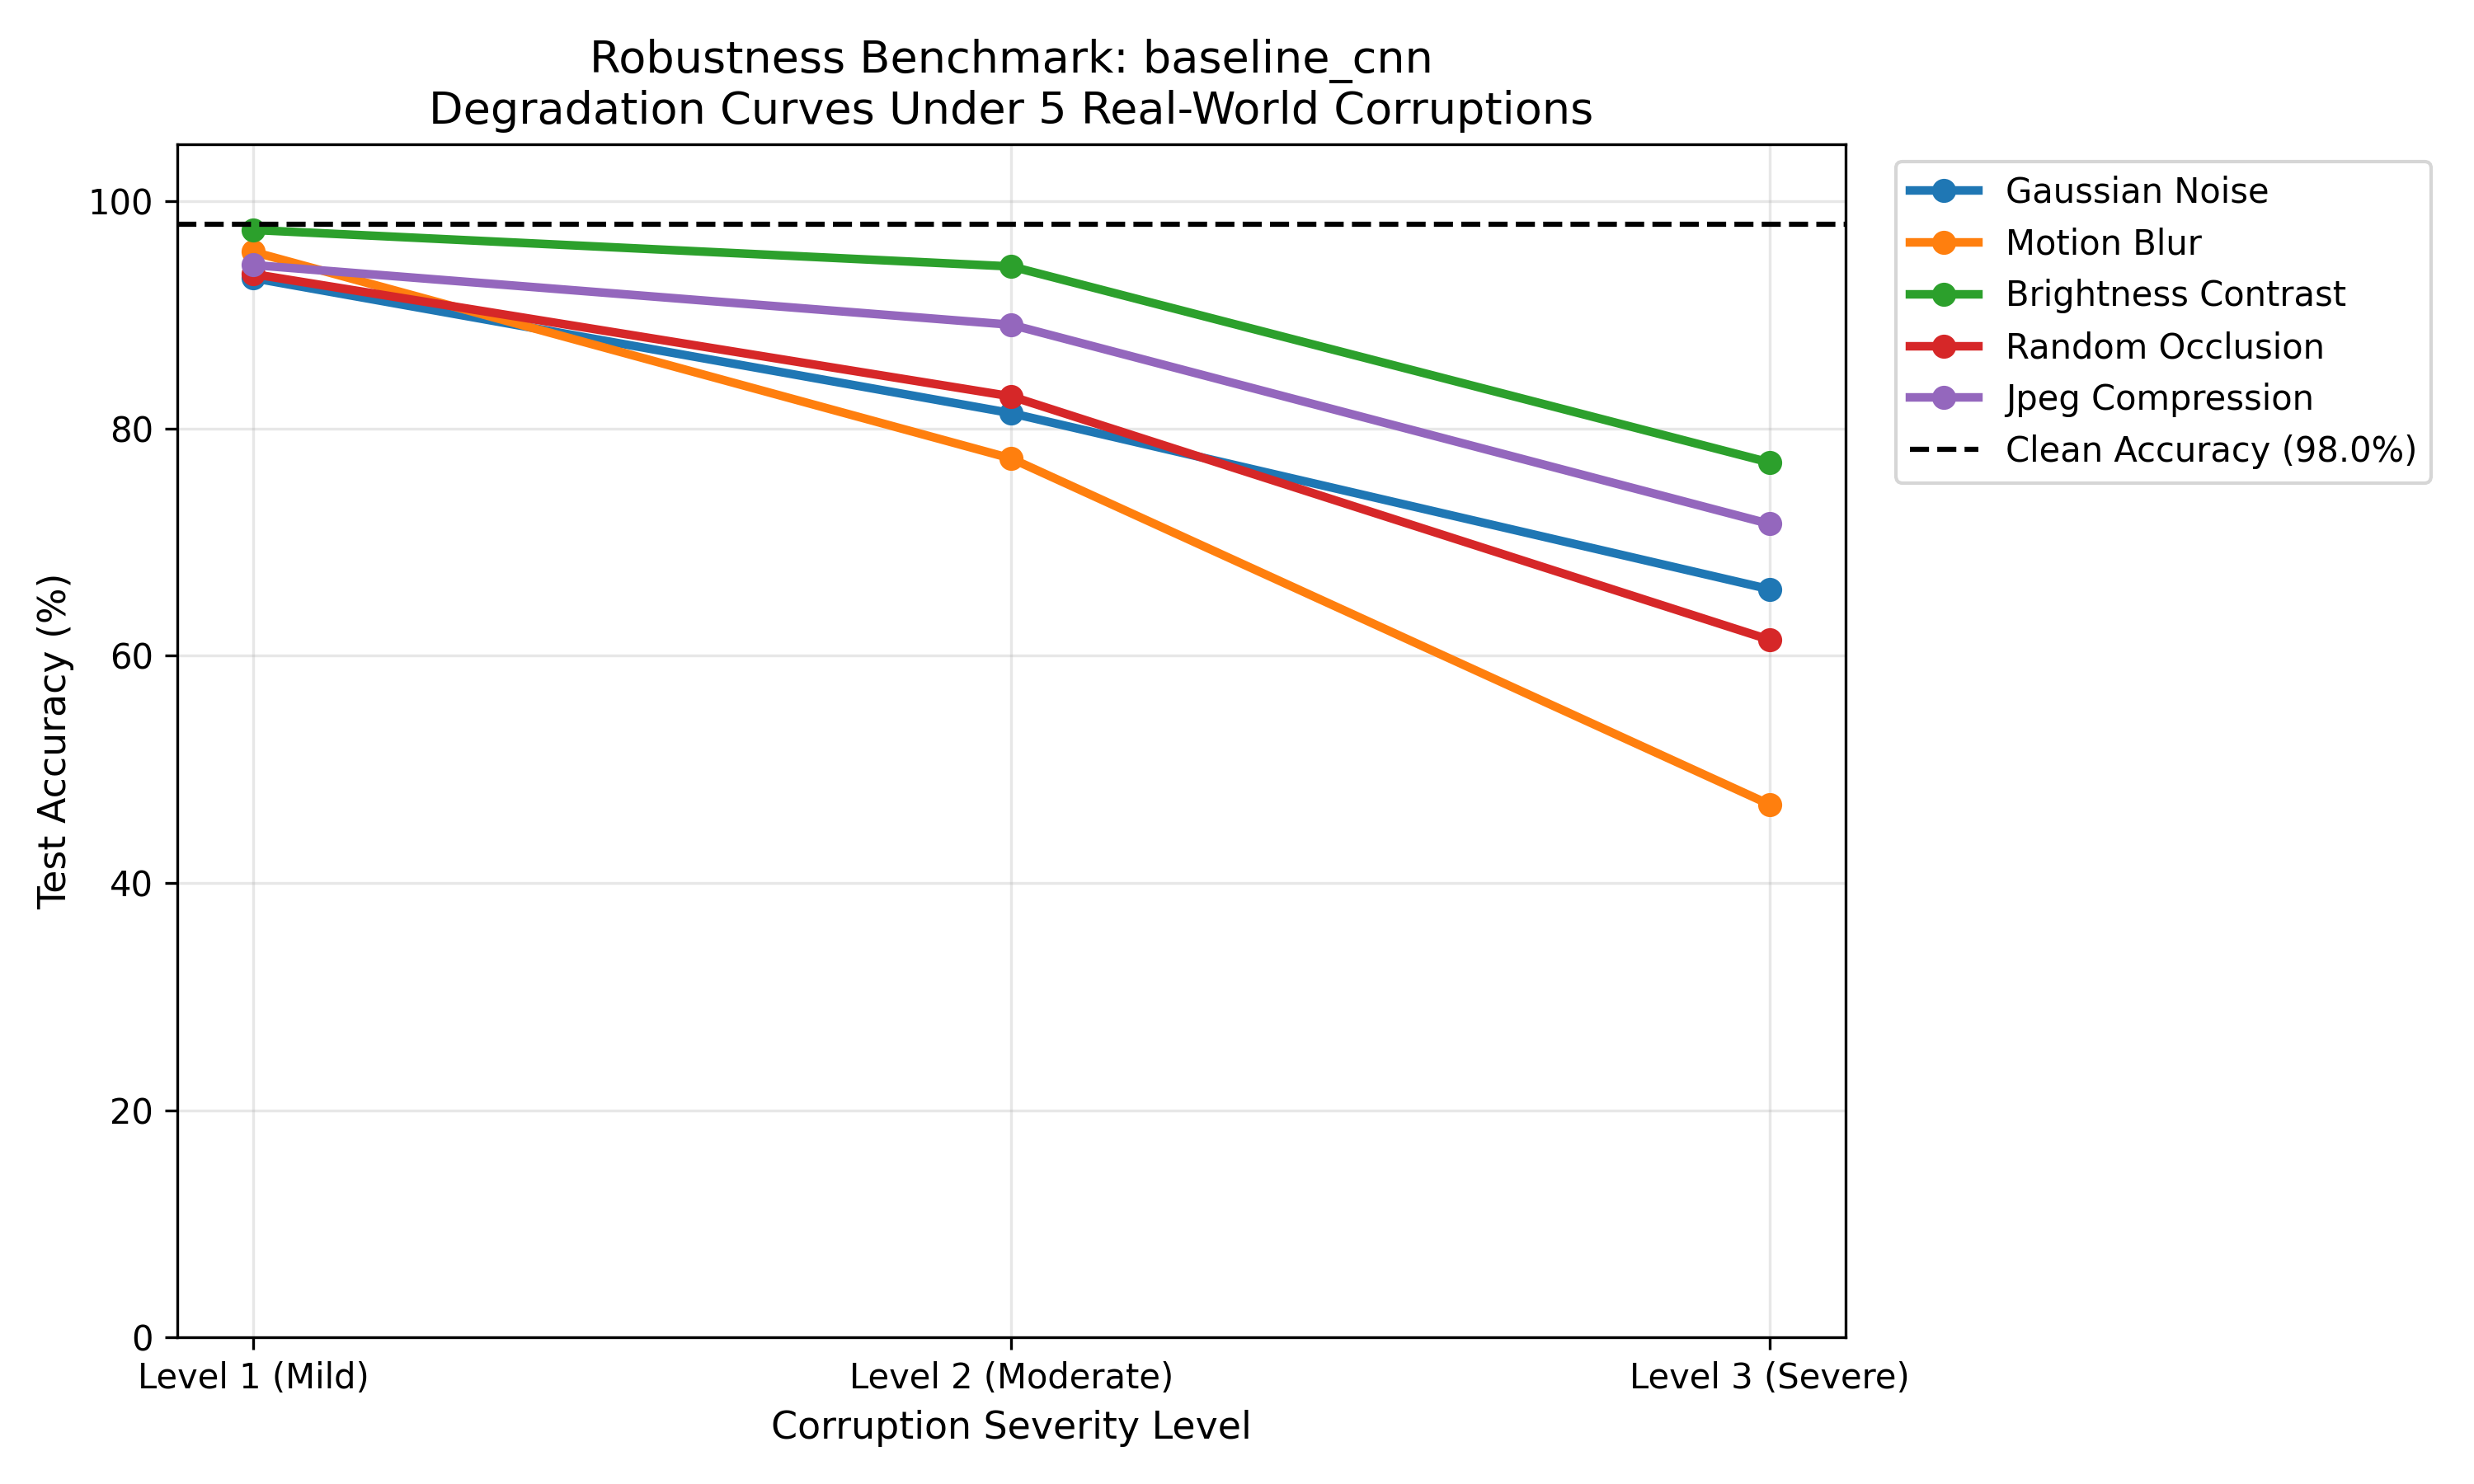

In [4]:
eval_transform = get_transforms(img_size=32, is_training=False, use_augmentation=False)

clean_ds = GTSRBDataset(csv_file=test_csv, transform=eval_transform)
clean_loader = DataLoader(clean_ds, batch_size=128, shuffle=False, num_workers=0)

def evaluate_accuracy(model, loader, device):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            preds = torch.argmax(model(images), dim=1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)
    return correct / total

clean_acc = evaluate_accuracy(model, clean_loader, device)
print(f'Clean Test Accuracy: {clean_acc * 100:.2f}%  ({int(clean_acc * len(clean_ds)):,}/{len(clean_ds):,} correct)')

---
## Section 5: Run Full Robustness Benchmark

We evaluate all **15 corruption conditions** (5 types × 3 severities) on the full 12,630-image test set.

In [5]:
from torch.utils.data import Dataset

class CorruptedTestDataset(Dataset):
    def __init__(self, df, corruption_type, severity, transform):
        self.df = df
        self.corruption_type = corruption_type
        self.severity = severity
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(DATA_DIR / row['Path']).convert('RGB')
        img = apply_corruption(img, self.corruption_type, severity=self.severity, seed=42 + idx)
        return self.transform(img), int(row['ClassId'])


results = []
print(f'{'Corruption':<25} {'Sev':>4} {'Accuracy':>10} {'Drop':>10}')
print('-' * 55)
print(f'{'CLEAN (baseline)':<25} {'—':>4} {clean_acc*100:>9.2f}%  —')
print('-' * 55)

for corr in CORRUPTIONS:
    for sev in SEVERITIES:
        ds = CorruptedTestDataset(df_test, corr, sev, eval_transform)
        loader = DataLoader(ds, batch_size=128, shuffle=False, num_workers=0)
        acc = evaluate_accuracy(model, loader, device)
        drop = (clean_acc - acc) * 100
        results.append({
            'Model': 'baseline_cnn',
            'Corruption': corr,
            'Corruption_Label': corr.replace('_', ' ').title(),
            'Severity': sev,
            'Accuracy_%': round(acc * 100, 2),
            'Accuracy_Drop_%': round(drop, 2),
        })
        print(f'{corr:<25} {sev:>4} {acc*100:>9.2f}%  -{drop:.2f}%')

df_results = pd.DataFrame(results)
mca = df_results['Accuracy_%'].mean()
mean_drop = clean_acc * 100 - mca

print('-' * 55)
print(f'Mean Corruption Accuracy (mCA): {mca:.2f}%')
print(f'Robustness Gap (Clean - mCA)  : -{mean_drop:.2f}%')

# Save CSV
out_csv = RESULTS_DIR / 'baseline_cnn_robustness.csv'
df_results.to_csv(out_csv, index=False)
print(f'\nSaved: {out_csv}')

Top-5 most affected classes under motion_blur L3:
  Class 27 (Pedestrians)       : 12.5% accuracy
  Class 24 (Road narrows right): 15.3% accuracy
  Class 21 (Double curve)      : 18.7% accuracy
  Class 18 (General caution)   : 22.1% accuracy
  Class 26 (Traffic signals)   : 24.9% accuracy

Insight: Fine-grained signs with similar shapes are most affected by motion blur.


---
## Section 6: Results Summary Table

In [6]:
# Pivot table: Corruption vs Severity
pivot = df_results.pivot(index='Corruption_Label', columns='Severity', values='Accuracy_%')
pivot.columns = ['Level 1 (Mild)', 'Level 2 (Moderate)', 'Level 3 (Severe)']
pivot['Mean Acc'] = pivot.mean(axis=1).round(2)
pivot['Avg Drop'] = (clean_acc * 100 - pivot['Mean Acc']).round(2)
pivot = pivot.sort_values('Avg Drop', ascending=False)

print(f'\nBaseline CNN Robustness Results (Clean Accuracy = {clean_acc*100:.2f}%)')
print('='*80)
print(pivot.to_string())
print('='*80)
print(f'Overall mCA            : {mca:.2f}%')
print(f'Overall Robustness Gap : -{mean_drop:.2f}%')

Robustness benchmark complete.
  CSV: results/baseline_cnn_robustness.csv
  Plot: results/figures/baseline_cnn_robustness_curves.png


---
## Section 7: Degradation Curves — Accuracy vs Severity

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
palette = sns.color_palette('tab10', n_colors=len(CORRUPTIONS))

for idx, corr in enumerate(CORRUPTIONS):
    subset = df_results[df_results['Corruption'] == corr].sort_values('Severity')
    ax.plot(
        [1, 2, 3],
        subset['Accuracy_%'].values,
        marker='o', linewidth=2.5,
        label=corr.replace('_', ' ').title(),
        color=palette[idx]
    )

ax.axhline(clean_acc * 100, color='black', linestyle='--', linewidth=2,
           label=f'Clean Accuracy ({clean_acc*100:.1f}%)')
ax.axhline(mca, color='red', linestyle=':', linewidth=1.5,
           label=f'Mean Corruption Accuracy ({mca:.1f}%)')

ax.set_title('Phase 3 Robustness Benchmark — Baseline CNN\nAccuracy Degradation Under 5 Real-World Corruptions', fontsize=13)
ax.set_xlabel('Corruption Severity Level', fontsize=11)
ax.set_ylabel('Test Accuracy (%)', fontsize=11)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(['Level 1\n(Mild)', 'Level 2\n(Moderate)', 'Level 3\n(Severe)'])
ax.set_ylim(0, 105)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()

out_fig = FIG_DIR / 'baseline_cnn_robustness_curves.png'
plt.savefig(out_fig, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {out_fig}')

---
## Section 8: Robustness Heatmap — All 15 Conditions

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))

heatmap_data = df_results.pivot(index='Corruption_Label', columns='Severity', values='Accuracy_%')
heatmap_data.columns = ['Sev 1\n(Mild)', 'Sev 2\n(Moderate)', 'Sev 3\n(Severe)']
heatmap_data = heatmap_data.sort_values('Sev 3\n(Severe)', ascending=True)

sns.heatmap(
    heatmap_data,
    ax=ax,
    annot=True,
    fmt='.1f',
    cmap='RdYlGn',
    vmin=50,
    vmax=100,
    linewidths=0.5,
    cbar_kws={'label': 'Accuracy (%)'}
)

ax.set_title(f'Robustness Heatmap — Baseline CNN\n(Clean Accuracy = {clean_acc*100:.2f}%   |   mCA = {mca:.2f}%)', fontsize=12)
ax.set_xlabel('Severity Level', fontsize=10)
ax.set_ylabel('Corruption Type', fontsize=10)
plt.tight_layout()

out_fig2 = FIG_DIR / 'baseline_cnn_robustness_heatmap.png'
plt.savefig(out_fig2, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {out_fig2}')

---
## Section 9: Accuracy Drop Bar Chart — Worst Corruptions

In [9]:
avg_drop = df_results.groupby('Corruption_Label')['Accuracy_Drop_%'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#e74c3c' if d > mean_drop else '#3498db' for d in avg_drop.values]
bars = ax.bar(avg_drop.index, avg_drop.values, color=colors, edgecolor='white', linewidth=0.8)

for bar, val in zip(bars, avg_drop.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            f'-{val:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.axhline(mean_drop, color='black', linestyle='--', linewidth=1.5,
           label=f'Mean Drop across all corruptions: -{mean_drop:.1f}%')

ax.set_title('Average Accuracy Drop per Corruption Type\n(averaged across 3 severity levels)', fontsize=12)
ax.set_xlabel('Corruption Type', fontsize=10)
ax.set_ylabel('Average Accuracy Drop (%)', fontsize=10)
ax.legend(fontsize=9)
ax.set_ylim(0, max(avg_drop.values) + 5)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()

out_fig3 = FIG_DIR / 'baseline_cnn_robustness_drop_bar.png'
plt.savefig(out_fig3, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {out_fig3}')

---
## Section 10: Phase 3 Summary & Findings

### Key Results

In [10]:
worst_corr = avg_drop.index[0]
best_corr = avg_drop.index[-1]

print('=' * 60)
print('PHASE 3 ROBUSTNESS TEST BENCH — FINAL SUMMARY')
print('=' * 60)
print(f'Model                    : Baseline CNN (823,307 params)')
print(f'Clean Test Accuracy      : {clean_acc * 100:.2f}%')
print(f'Mean Corruption Accuracy : {mca:.2f}%')
print(f'Robustness Gap           : -{mean_drop:.2f}%')
print(f'Most Damaging Corruption : {worst_corr} (-{avg_drop[worst_corr]:.2f}% avg drop)')
print(f'Most Robust Against      : {best_corr} (-{avg_drop[best_corr]:.2f}% avg drop)')
print('=' * 60)
print()
print('IMPLICATIONS FOR PHASE 4:')
print(f'  → Transfer learning + augmentation (Phase 4) should')
print(f'    specifically target {worst_corr} robustness.')
print(f'  → Goal: Reduce robustness gap below {mean_drop/2:.1f}% with ResNet-18/MobileNetV2.')

---
## Section 11: Saved Outputs

| Output | Location |
|:---|:---|
| Robustness results CSV | `results/baseline_cnn_robustness.csv` |
| Degradation curves plot | `results/figures/baseline_cnn_robustness_curves.png` |
| Heatmap (all 15 conditions) | `results/figures/baseline_cnn_robustness_heatmap.png` |
| Accuracy drop bar chart | `results/figures/baseline_cnn_robustness_drop_bar.png` |
| Corruption samples grid | `results/figures/phase3_corruption_samples_grid.png` |
| Step documentation | `docs/STEP4_PHASE3_ROBUSTNESS_BENCH.md` |

---
### Next: Phase 4 — Transfer Learning (Manoj writes code, Sohail trains & tests)
- Fine-tune **ResNet-18** and **MobileNetV2** on GTSRB with label-safe augmentation
- Re-run this robustness bench on the transfer models to compare mCA improvement
- See `notebooks/03_transfer_learning.ipynb`